# Part 2: Fine-Tuning Stable Diffusion 1.5

## Setup

In [1]:
# papermill parameter: the real git commit hash, passed in when this runs off-repo (e.g. on Colab)
COMMIT_OVERRIDE = ""


In [2]:
# Parameters
COMMIT_OVERRIDE = "242cab5"


In [3]:
import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
# empty on Colab unless COMMIT_OVERRIDE is passed in (papermill -p COMMIT_OVERRIDE <hash>): this
# notebook runs standalone on the Colab VM, which has no copy of the git repo to read HEAD from
commit = COMMIT_OVERRIDE or subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})


{'commit': '242cab5', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [4]:
# lab rule: all required Part 2 work MUST run on one 16 GB GPU (Kaggle T4/P100 or Colab T4);
# the T4 has no native bf16 (torch reports it as "supported" but it is emulated), so this notebook uses fp16.
ALLOW_OTHER_GPU = False

gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
is_t4 = "T4" in gpu_name
print("GPU:", gpu_name, "| T4:", is_t4)
if not is_t4 and not ALLOW_OTHER_GPU:
    raise RuntimeError(
        f"this notebook requires a Colab T4 GPU (lab rule: one 16 GB GPU); got {gpu_name!r}. "
        "Select Kernel -> Colab -> New Colab Server -> T4, or set ALLOW_OTHER_GPU = True to override."
    )

# fp16 vs fp32 matmul precision check (this notebook trains in fp16; confirms the math is sane
# on this GPU before using it for anything real). A per-element relative error is unstable near
# zero (some matmul output entries land close to 0 by chance, blowing up any x/0-ish ratio), so
# this uses the overall (Frobenius-norm) relative error instead, which is well-conditioned.
if torch.cuda.is_available():
    a = torch.randn(1024, 1024, device="cuda") / 32
    b = torch.randn(1024, 1024, device="cuda") / 32
    c32 = a @ b
    c16 = (a.half() @ b.half()).float()
    rel_err = ((c16 - c32).norm() / c32.norm()).item()
    print(f"fp16 vs fp32 matmul: relative error = {rel_err:.2e}")
    assert torch.isfinite(c16).all(), "fp16 matmul produced inf/nan"
    print("no inf/nan in the fp16 result")


GPU: Tesla T4 | T4: True


fp16 vs fp32 matmul: relative error = 3.60e-04
no inf/nan in the fp16 result


In [5]:
import collections, hashlib, io, json as j
from pathlib import Path
from PIL import Image
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"
DRIVE_ROOT = Path("/content/drive/MyDrive/DATA266-Lab2/p2")
DATA_DIR = Path("/content/p2_data")  # local VM disk -- not on Drive, training data never needs to survive a restart


### Installs (pinned versions)

In [6]:
import importlib.metadata as im

# pinned to the versions this notebook was built and timed against (verified in the Stage P2-0 environment
# check); reinstalling the same pin is a fast no-op when they already match, and guarantees the pin is real.
# torchao is pinned because peft 0.21.2 raises (not just skips) when a torchao install is present but
# too old for peft's own LoRA-dispatch check; this Colab image ships 0.10.0, which trips exactly that.
PINS = {"diffusers": "0.42.1", "peft": "0.21.2", "accelerate": "1.15.0", "datasets": "4.8.5",
        "imagehash": "4.3.2", "torchao": "0.18.0"}
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + [f"{pkg}=={ver}" for pkg, ver in PINS.items()], check=True)
for pkg in PINS:
    print(f"{pkg}: {im.version(pkg)}")


diffusers: 0.42.1
peft: 0.21.2
accelerate: 1.15.0
datasets: 4.8.5
imagehash: 4.3.2
torchao: 0.18.0


In [7]:
import urllib.request

# the official example script, pulled from the diffusers tag that matches the pinned version above -- never
# vendored by hand, so it can't silently drift from what's actually installed
DIFFUSERS_VERSION = im.version("diffusers")
SCRIPT_URL = f"https://raw.githubusercontent.com/huggingface/diffusers/v{DIFFUSERS_VERSION}/examples/text_to_image/train_text_to_image_lora.py"
TRAIN_SCRIPT = Path("/content/train_text_to_image_lora.py")
urllib.request.urlretrieve(SCRIPT_URL, TRAIN_SCRIPT)
print("downloaded", SCRIPT_URL)
print("sha256:", hashlib.sha256(TRAIN_SCRIPT.read_bytes()).hexdigest())


downloaded https://raw.githubusercontent.com/huggingface/diffusers/v0.42.1/examples/text_to_image/train_text_to_image_lora.py
sha256: 7d67f3ed756a3cb79183153349ebb2d141c999f898da964edb2ea4af5d72d6ab


### Google Drive and Hugging Face

In [8]:
# Drive is mounted BEFORE this notebook runs, from the CLI: `colab drivemount -s <session>`
# (its credential-propagation handling only works through that command, not a plain drive.mount()
# call made from inside a notebook executed over colab-cli).
assert Path("/content/drive/MyDrive").exists(), "Drive not mounted -- run 'colab drivemount -s <session>' first"
print("Drive already mounted at /content/drive")


Drive already mounted at /content/drive


In [9]:
# Hugging Face auth is set up BEFORE this notebook runs, from the CLI: copy the local token file with
# `colab upload -s <session> ~/.cache/huggingface/token /root/.cache/huggingface/token`.
# Colab Secrets and getpass don't apply here -- there is no interactive prompt to answer, and the
# token is never read, printed or stored by this notebook or by this session.
from huggingface_hub import HfApi
print("HF username:", HfApi().whoami()["name"])


HF username: itzmnv


## Fixed evaluation prompts

The 20 prompts used in every generation run (section 2.3), written before training so they can't be tuned to. Embedded here because the Colab VM cannot read the repo; the check below only runs where `eval/p2_prompts_manav*.json` actually exist (a Mac test from inside the repo), and is skipped on the VM.

In [10]:
PROMPTS = [{'id': 'P01', 'type': 'in_domain', 'prompt': 'a red fish with a gold crown on its head', 'test_image_id': 35}, {'id': 'P02', 'type': 'in_domain', 'prompt': 'a very cute looking pokemon with big eyes', 'test_image_id': 44}, {'id': 'P03', 'type': 'in_domain', 'prompt': 'a bird with a long beak flying through the air', 'test_image_id': 97}, {'id': 'P04', 'type': 'in_domain', 'prompt': 'a yellow and white cartoon character with a red eye', 'test_image_id': 100}, {'id': 'P05', 'type': 'in_domain', 'prompt': 'a gray and yellow dragon with large horns', 'test_image_id': 392}, {'id': 'P06', 'type': 'in_domain', 'prompt': 'a robot with a yellow helmet and green legs', 'test_image_id': 491}, {'id': 'P07', 'type': 'in_domain', 'prompt': 'a cartoon picture of a bear holding a baseball bat', 'test_image_id': 19}, {'id': 'P08', 'type': 'in_domain', 'prompt': 'a black and white picture of a cat wearing a witches hat', 'test_image_id': 639}, {'id': 'P09', 'type': 'in_domain', 'prompt': 'a very cute looking animal with big ears', 'test_image_id': 418}, {'id': 'P10', 'type': 'in_domain', 'prompt': 'a cartoon character with pink hair and a pom pom on top of it', 'test_image_id': 757}, {'id': 'P11', 'type': 'out_of_domain', 'prompt': 'a red double-decker bus on a rainy london street'}, {'id': 'P12', 'type': 'out_of_domain', 'prompt': 'a bowl of ramen with chopsticks on a wooden table'}, {'id': 'P13', 'type': 'out_of_domain', 'prompt': 'a lighthouse on a rocky coast at sunset'}, {'id': 'P14', 'type': 'out_of_domain', 'prompt': 'an astronaut riding a bicycle on the moon'}, {'id': 'P15', 'type': 'out_of_domain', 'prompt': 'a portrait of an old fisherman wearing a yellow raincoat'}, {'id': 'P16', 'type': 'compositional', 'prompt': 'two cartoon creatures, one red and one blue, standing side by side'}, {'id': 'P17', 'type': 'compositional', 'prompt': 'a small green creature sitting on top of a large orange creature'}, {'id': 'P18', 'type': 'compositional', 'prompt': 'three yellow creatures in a row, the middle one wearing a hat'}, {'id': 'P19', 'type': 'compositional', 'prompt': 'a blue fish-like creature on the left and a purple bird on the right'}, {'id': 'P20', 'type': 'compositional', 'prompt': 'a white cat-like creature holding a red ball under a tree'}]

print(len(PROMPTS), "fixed prompts embedded |", collections.Counter(p["type"] for p in PROMPTS))

_eval_dir = Path("eval")
_f1, _f2 = _eval_dir / "p2_prompts_manav.json", _eval_dir / "p2_prompts_manav_ood_comp.json"
if _f1.exists() and _f2.exists():
    _from_files = j.loads(_f1.read_text()) + j.loads(_f2.read_text())
    assert PROMPTS == _from_files, "embedded PROMPTS does not match eval/p2_prompts_manav*.json"
    print("embedded prompts match eval/p2_prompts_manav*.json")
else:
    print("eval files not found here (expected on the Colab VM) -- skipping the equality check")


20 fixed prompts embedded | Counter({'in_domain': 10, 'out_of_domain': 5, 'compositional': 5})
eval files not found here (expected on the Colab VM) -- skipping the equality check


## 2.1 Data Preparation

### Load the dataset

In [11]:
from datasets import load_dataset, Image as HFImage

ds = load_dataset("reach-vb/pokemon-blip-captions", split="train").cast_column("image", HFImage(decode=False))
print(ds)
print("rows before cleaning:", len(ds))


Dataset({
    features: ['image', 'text'],
    num_rows: 833
})
rows before cleaning: 833


### Remove corrupted, exact-duplicate and near-duplicate images

In [12]:
import imagehash

PHASH_MAX_HAMMING = 4


def open_image(data):
    Image.open(io.BytesIO(data)).verify()
    img = Image.open(io.BytesIO(data))
    img.load()
    return img.convert("RGB")


print(f"near duplicate = perceptual hash (phash), Hamming distance <= {PHASH_MAX_HAMMING}")

corrupted, exact, near, keep = [], [], [], []
seen_pixels, seen_phash = {}, []
for i in range(len(ds)):
    try:
        img = open_image(ds[i]["image"]["bytes"])
    except Exception:
        corrupted.append(i)
        continue
    pixel_key = hashlib.md5(img.tobytes()).hexdigest()
    if pixel_key in seen_pixels:
        exact.append((seen_pixels[pixel_key], i))
        continue
    seen_pixels[pixel_key] = i
    ph = imagehash.phash(img)
    dup = next((j for j, h in seen_phash if ph - h <= PHASH_MAX_HAMMING), None)
    if dup is not None:
        near.append((dup, i))
        continue
    seen_phash.append((i, ph))
    keep.append(i)

print("corrupted:", len(corrupted))
print("exact duplicates:", len(exact))
print("near duplicates:", len(near))
print("rows after cleaning:", len(keep))
for a, b in near[:5]:
    print("  near-dup pair kept=%d dropped=%d: %r | %r" % (a, b, ds[a]["text"], ds[b]["text"]))


near duplicate = perceptual hash (phash), Hamming distance <= 4


corrupted: 0
exact duplicates: 0
near duplicates: 8
rows after cleaning: 825
  near-dup pair kept=605 dropped=606: 'a drawing of a deer with a bow on its head' | 'a pink and yellow deer with a yellow bow on its head'
  near-dup pair kept=605 dropped=607: 'a drawing of a deer with a bow on its head' | 'a green and yellow animal with a yellow bow on its head'
  near-dup pair kept=605 dropped=608: 'a drawing of a deer with a bow on its head' | 'a cartoon deer with a yellow bow on its head'
  near-dup pair kept=712 dropped=714: 'a picture of a yellow butterfly on a white background' | 'a colorful butterfly is shown on a white background'
  near-dup pair kept=712 dropped=716: 'a picture of a yellow butterfly on a white background' | 'a picture of a butterfly that is orange and green'


### Train and test split (90/10, seed 266, after cleaning)

In [13]:
def split(ids, seed=SEED, test_frac=0.1):
    ids = sorted(ids)
    random.Random(seed).shuffle(ids)
    n_test = round(len(ids) * test_frac)
    return sorted(ids[n_test:]), sorted(ids[:n_test])


train_ids, test_ids = split(keep)
print("train:", len(train_ids), "| test:", len(test_ids))
print("same test ids on a second run:", split(keep)[1] == test_ids)
print("train and test overlap:", len(set(train_ids) & set(test_ids)))
print("first 10 test ids:", test_ids[:10])


train: 743 | test: 82
same test ids on a second run: True
train and test overlap: 0
first 10 test ids: [9, 14, 19, 22, 23, 25, 35, 44, 53, 68]


### Resize to 512x512 and save

In [14]:
def to_512(img):
    s = min(img.size)
    left, top = (img.width - s) // 2, (img.height - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((512, 512), Image.LANCZOS)


sizes = {i: open_image(ds[i]["image"]["bytes"]).size for i in keep}
print("non-square images (center cropped):", sum(w != h for w, h in sizes.values()))

for name, ids in [("train", train_ids), ("test", test_ids)]:
    out = DATA_DIR / name
    out.mkdir(parents=True, exist_ok=True)
    with open(out / "metadata.jsonl", "w") as f:
        for i in ids:
            file_name = "%04d.png" % i
            to_512(open_image(ds[i]["image"]["bytes"])).save(out / file_name)
            f.write(j.dumps({"file_name": file_name, "text": ds[i]["text"]}) + "\n")
    print(name, len(list(out.glob("*.png"))), "images saved in", out)

(DRIVE_ROOT / "split_ids.json").write_text(j.dumps({"train_ids": train_ids, "test_ids": test_ids, "seed": SEED}, indent=2))
print("split ids saved to", DRIVE_ROOT / "split_ids.json")

train_check = load_dataset("imagefolder", data_files={"train": str(DATA_DIR / "train" / "**")}, split="train")
print("loads like the diffusers script:", train_check.column_names, len(train_check), train_check[0]["image"].size)


non-square images (center cropped): 0


train 743 images saved in /content/p2_data/train


test 82 images saved in /content/p2_data/test
split ids saved to /content/drive/MyDrive/DATA266-Lab2/p2/split_ids.json


Resolving data files:   0%|          | 0/744 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

loads like the diffusers script: ['image', 'text'] 743 (512, 512)


### Dataset description, limitations and biases

In [15]:
caps = [ds[i]["text"] for i in keep]
words = [len(c.split()) for c in caps]
print("caption words: min", min(words), "| median", int(np.median(words)), "| max", max(words))
print("most common caption starts:", collections.Counter(" ".join(c.split()[:3]) for c in caps).most_common(5))
print("captions with the word pokemon:", sum("pokemon" in c.lower() for c in caps))
print("captions with 'white background':", sum("white background" in c for c in caps))

COLOR_WORDS = ["red", "blue", "green", "yellow", "orange", "purple", "pink", "black", "white", "gray", "grey", "brown"]
color_counts = collections.Counter(w for c in caps for w in COLOR_WORDS if w in c.lower())
print("colour words, captions mentioning each:", color_counts.most_common())
print("captions with at least one colour word:", sum(any(w in c.lower() for w in COLOR_WORDS) for c in caps), "of", len(caps))


caption words: min 6 | median 9 | max 16
most common caption starts: [('a drawing of', 312), ('a cartoon character', 89), ('a very cute', 51), ('a blue and', 41), ('a picture of', 23)]
captions with the word pokemon: 116
captions with 'white background': 15
colour words, captions mentioning each: [('blue', 170), ('white', 147), ('yellow', 113), ('green', 94), ('black', 85), ('red', 82), ('pink', 81), ('purple', 39), ('orange', 18), ('brown', 15), ('gray', 14), ('grey', 2)]
captions with at least one colour word: 472 of 825


**Dataset.** Pokemon BLIP Captions (`reach-vb/pokemon-blip-captions`, a copy of the Lambda Labs set). Each row is one Pokemon picture with one short caption written by the BLIP captioning model. All counts above are printed by this notebook, not typed in by hand.

**Limitation 1: caption style.** The captions come from BLIP, not from people. They are short (see the word-count line above) and generic -- most start with "a drawing of" or "a cartoon character" and rarely name "pokemon" at all. The model learns this vague captioning style, so prompts written like real descriptions may match it less well than prompts written in the same flat style.

**Limitation 2: colour over identity.** Captions describe creatures mostly by colour (see the colour-word counts above) rather than species or pose, and almost none mention the background even though every image has a plain white one. The model will likely lean on colour words to tell prompts apart and add a white background by default, regardless of what the prompt actually asks for.

**License.** CC BY-NC-SA 4.0. The characters are copyrighted, so this data and any model trained on it are for non-commercial research only.

## 2.2 Fine-Tuning

### Training config

In [16]:
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"


def run_config(rank, steps, checkpointing_steps):
    # shared config for both LoRA runs -- only rank (and, once the timing test below fixes it, steps and
    # checkpointing_steps) differs between the rank-8 and rank-32 runs
    return {
        "pretrained_model_name_or_path": BASE_MODEL,
        "resolution": 512,
        "center_crop": True,
        "random_flip": True,
        "train_batch_size": 1,
        "gradient_accumulation_steps": 4,
        "learning_rate": 1e-4,
        "lr_scheduler": "cosine",
        "lr_warmup_steps": max(1, steps // 10),
        "snr_gamma": 5.0,
        "mixed_precision": "fp16",
        "gradient_checkpointing": True,
        "seed": SEED,
        "max_train_steps": steps,
        "checkpointing_steps": checkpointing_steps,
        "rank": rank,
        # the script joins its own "logs" subdir under output_dir, and output_dir is already a
        # Drive path for every real run, so the tensorboard event files land on Drive for free
        "report_to": "tensorboard",
    }


STEPS = 2200  # lab 2.2: both runs use the same step budget
CHECKPOINTING_STEPS = 500

cfg8, cfg32 = run_config(8, STEPS, CHECKPOINTING_STEPS), run_config(32, STEPS, CHECKPOINTING_STEPS)
print(cfg8)
diff_keys = {k for k in cfg8 if cfg8[k] != cfg32[k]}
assert diff_keys == {"rank"}, diff_keys
print("the two configs differ only in:", diff_keys)


{'pretrained_model_name_or_path': 'stable-diffusion-v1-5/stable-diffusion-v1-5', 'resolution': 512, 'center_crop': True, 'random_flip': True, 'train_batch_size': 1, 'gradient_accumulation_steps': 4, 'learning_rate': 0.0001, 'lr_scheduler': 'cosine', 'lr_warmup_steps': 220, 'snr_gamma': 5.0, 'mixed_precision': 'fp16', 'gradient_checkpointing': True, 'seed': 266, 'max_train_steps': 2200, 'checkpointing_steps': 500, 'rank': 8, 'report_to': 'tensorboard'}
the two configs differ only in: {'rank'}


### Training wrapper and launch/wait utilities

In [17]:
WRAPPER = Path("/content/train_wrapper.py")
WRAPPER.write_text('import argparse, json, re, subprocess, time\nfrom pathlib import Path\n\n\ndef parse_args():\n    p = argparse.ArgumentParser()\n    p.add_argument("--run_name", required=True)\n    p.add_argument("--output_dir", required=True)\n    p.add_argument("--train_script", required=True)\n    p.add_argument("--train_data_dir", required=True)\n    p.add_argument("--pretrained_model_name_or_path", required=True)\n    p.add_argument("--resolution", type=int, required=True)\n    p.add_argument("--train_batch_size", type=int, required=True)\n    p.add_argument("--gradient_accumulation_steps", type=int, required=True)\n    p.add_argument("--learning_rate", type=float, required=True)\n    p.add_argument("--lr_scheduler", required=True)\n    p.add_argument("--lr_warmup_steps", type=int, required=True)\n    p.add_argument("--snr_gamma", type=float, required=True)\n    p.add_argument("--mixed_precision", required=True)\n    p.add_argument("--rank", type=int, required=True)\n    p.add_argument("--max_train_steps", type=int, required=True)\n    p.add_argument("--checkpointing_steps", type=int, required=True)\n    p.add_argument("--seed", type=int, required=True)\n    p.add_argument("--report_to", default="none")\n    p.add_argument("--center_crop", action="store_true")\n    p.add_argument("--random_flip", action="store_true")\n    p.add_argument("--gradient_checkpointing", action="store_true")\n    return p.parse_args()\n\n\ndef latest_checkpoint(output_dir):\n    ckpts = sorted(Path(output_dir).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1]))\n    return ckpts[-1] if ckpts else None\n\n\ndef gpu_memory_mib():\n    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],\n                          capture_output=True, text=True).stdout.strip()\n    return int(out.splitlines()[0]) if out else 0\n\n\ndef steps_from_log(text):\n    matches = re.findall(r"(\\d+)/(\\d+)\\s*\\[", text)\n    return int(matches[-1][0]) if matches else 0\n\n\ndef write_stats(stats_path, run_name, start_time, end_time, peak_mem, steps_finished, max_train_steps, exit_code, log_text, finished):\n    now = end_time if end_time is not None else time.time()\n    stats = {\n        "run_name": run_name,\n        "start_time": start_time,\n        "end_time": end_time,\n        "wall_clock_s": now - start_time,\n        "gpu_hours": (now - start_time) / 3600,\n        "peak_memory_mib": peak_mem,\n        "steps_finished": steps_finished,\n        "max_train_steps": max_train_steps,\n        "exit_code": exit_code,\n        "last_log_lines": log_text.splitlines()[-20:],\n        "finished": finished,  # None = still running, True = finished ok, False = finished with an error\n    }\n    stats_path.write_text(json.dumps(stats, indent=2))\n    return stats\n\n\ndef main():\n    args = parse_args()\n    out_dir = Path(args.output_dir)\n    out_dir.mkdir(parents=True, exist_ok=True)\n    log_path = out_dir / "train.log"\n    stats_path = out_dir / "stats.json"\n\n    cmd = [\n        "accelerate", "launch", args.train_script,\n        f"--pretrained_model_name_or_path={args.pretrained_model_name_or_path}",\n        f"--train_data_dir={args.train_data_dir}",\n        f"--resolution={args.resolution}",\n        f"--train_batch_size={args.train_batch_size}",\n        f"--gradient_accumulation_steps={args.gradient_accumulation_steps}",\n        f"--learning_rate={args.learning_rate}",\n        f"--lr_scheduler={args.lr_scheduler}",\n        f"--lr_warmup_steps={args.lr_warmup_steps}",\n        f"--snr_gamma={args.snr_gamma}",\n        f"--mixed_precision={args.mixed_precision}",\n        f"--rank={args.rank}",\n        f"--max_train_steps={args.max_train_steps}",\n        f"--checkpointing_steps={args.checkpointing_steps}",\n        f"--seed={args.seed}",\n        f"--report_to={args.report_to}",\n        f"--output_dir={out_dir}",\n    ]\n    for flag, val in [("center_crop", args.center_crop), ("random_flip", args.random_flip),\n                       ("gradient_checkpointing", args.gradient_checkpointing)]:\n        if val:\n            cmd.append(f"--{flag}")\n\n    if latest_checkpoint(out_dir) is not None:\n        cmd.append("--resume_from_checkpoint=latest")\n\n    start_time = time.time()\n    peak_mem, last_write = 0, 0.0\n    with open(log_path, "a") as log_f:\n        proc = subprocess.Popen(cmd, stdout=log_f, stderr=subprocess.STDOUT)\n        while proc.poll() is None:\n            peak_mem = max(peak_mem, gpu_memory_mib())\n            if time.time() - last_write > 10:\n                log_text = log_path.read_text(errors="replace")\n                write_stats(stats_path, args.run_name, start_time, None, peak_mem,\n                            steps_from_log(log_text), args.max_train_steps, None, log_text, finished=None)\n                last_write = time.time()\n            time.sleep(2)\n\n    end_time = time.time()\n    log_text = log_path.read_text(errors="replace")\n    stats = write_stats(stats_path, args.run_name, start_time, end_time, peak_mem,\n                         steps_from_log(log_text), args.max_train_steps, proc.returncode, log_text,\n                         finished=(proc.returncode == 0))\n    print(json.dumps(stats, indent=2))\n\n\nif __name__ == "__main__":\n    main()\n')
print("wrote", WRAPPER)


wrote /content/train_wrapper.py


In [18]:
import time


def launch_run(run_name, rank, steps, checkpointing_steps):
    # idempotent: a finished run is never re-launched; a partial run resumes from its own checkpoint
    run_dir = DRIVE_ROOT / "runs" / run_name
    stats_path = run_dir / "stats.json"
    if stats_path.exists() and j.loads(stats_path.read_text()).get("finished") is True:
        print(f"{run_name}: already trained")
        return None
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg = run_config(rank, steps, checkpointing_steps)
    cmd = ["python3", str(WRAPPER), "--run_name", run_name, "--output_dir", str(run_dir),
           "--train_script", str(TRAIN_SCRIPT), "--train_data_dir", str(DATA_DIR / "train"),
           "--pretrained_model_name_or_path", cfg["pretrained_model_name_or_path"],
           "--resolution", str(cfg["resolution"]), "--train_batch_size", str(cfg["train_batch_size"]),
           "--gradient_accumulation_steps", str(cfg["gradient_accumulation_steps"]),
           "--learning_rate", str(cfg["learning_rate"]), "--lr_scheduler", cfg["lr_scheduler"],
           "--lr_warmup_steps", str(cfg["lr_warmup_steps"]), "--snr_gamma", str(cfg["snr_gamma"]),
           "--mixed_precision", cfg["mixed_precision"], "--rank", str(cfg["rank"]),
           "--max_train_steps", str(cfg["max_train_steps"]), "--checkpointing_steps", str(cfg["checkpointing_steps"]),
           "--seed", str(cfg["seed"]), "--report_to", cfg["report_to"],
           "--center_crop", "--random_flip", "--gradient_checkpointing"]
    log = open(run_dir / "launch.log", "a")
    proc = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    print(f"{run_name}: started, pid {proc.pid}")
    return proc.pid


def wait_for_run(run_name, poll_s=60, timeout_s=None):
    # safe to re-run: it only reads the stats file, never starts anything
    run_dir = DRIVE_ROOT / "runs" / run_name
    stats_path = run_dir / "stats.json"
    t0 = time.time()
    while True:
        if stats_path.exists():
            stats = j.loads(stats_path.read_text())
            if stats.get("finished") is not None:
                print(f"{run_name}: finished, exit code {stats['exit_code']}, "
                      f"{stats['steps_finished']}/{stats['max_train_steps']} steps, "
                      f"{stats['gpu_hours']:.2f} GPU-hours")
                return stats
            print(f"{run_name}: step {stats['steps_finished']}/{stats['max_train_steps']}, "
                  f"{time.time() - t0:.0f}s elapsed")
        else:
            print(f"{run_name}: not started yet ({time.time() - t0:.0f}s elapsed)")
        if timeout_s and time.time() - t0 > timeout_s:
            print(f"{run_name}: timeout after {timeout_s}s, still running")
            return None
        time.sleep(poll_s)


### Trainable parameters

In [19]:
from safetensors.torch import load_file


def count_lora_params(run_dir):
    # counted from the saved weights themselves, not estimated from the rank
    path = Path(run_dir) / "pytorch_lora_weights.safetensors"
    state = load_file(str(path))
    return sum(t.numel() for t in state.values())


### Timing test (50 steps, rank 8 then rank 32, foreground)

In [20]:
TIMING_STEPS = 50
TARGET_MINUTES = 90
CRASH_BUDGET_MINUTES = 20

timing_results = {}
for rank in (8, 32):
    run_name = f"timing_r{rank}"
    run_dir = DRIVE_ROOT / "runs" / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    stats_path = run_dir / "stats.json"
    already = stats_path.exists() and j.loads(stats_path.read_text()).get("finished") is True
    if already:
        print(f"timing run: rank {rank} already trained, reusing its saved stats")
    else:
        cfg = run_config(rank, TIMING_STEPS, TIMING_STEPS + 1)  # +1: never trigger a mid-timing checkpoint
        cmd = ["python3", str(WRAPPER), "--run_name", run_name, "--output_dir", str(run_dir),
               "--train_script", str(TRAIN_SCRIPT), "--train_data_dir", str(DATA_DIR / "train"),
               "--pretrained_model_name_or_path", cfg["pretrained_model_name_or_path"],
               "--resolution", str(cfg["resolution"]), "--train_batch_size", str(cfg["train_batch_size"]),
               "--gradient_accumulation_steps", str(cfg["gradient_accumulation_steps"]),
               "--learning_rate", str(cfg["learning_rate"]), "--lr_scheduler", cfg["lr_scheduler"],
               "--lr_warmup_steps", str(cfg["lr_warmup_steps"]), "--snr_gamma", str(cfg["snr_gamma"]),
               "--mixed_precision", cfg["mixed_precision"], "--rank", str(cfg["rank"]),
               "--max_train_steps", str(cfg["max_train_steps"]), "--checkpointing_steps", str(cfg["checkpointing_steps"]),
               "--seed", str(cfg["seed"]), "--report_to", cfg["report_to"],
               "--center_crop", "--random_flip", "--gradient_checkpointing"]
        print(f"timing run: rank {rank}, {TIMING_STEPS} steps, in the foreground...")
        subprocess.run(cmd, check=True)

    stats = j.loads(stats_path.read_text())
    if not stats.get("finished"):
        print("last log lines:")
        for line in stats.get("last_log_lines", []):
            print("  ", line)
        raise RuntimeError(f"timing run {run_name} did not finish (exit code {stats.get('exit_code')}); see log lines above")
    sec_per_step = stats["wall_clock_s"] / max(1, stats["steps_finished"])
    peak_gb = stats["peak_memory_mib"] / 1024
    verdict = "PASS" if peak_gb < 16 else "FAIL"
    n_params = count_lora_params(run_dir)
    timing_results[rank] = {"sec_per_step": sec_per_step, "peak_gb": peak_gb, "verdict": verdict, "stats": stats, "params": n_params}
    print(f"  rank {rank}: {sec_per_step:.2f} s/step | peak {peak_gb:.2f} GB ({verdict}) | {n_params:,} trainable LoRA parameters")

print()
print(f"suggested STEPS so a full run takes at most {TARGET_MINUTES} minutes on this T4:")
for rank, r in timing_results.items():
    suggested_steps = int((TARGET_MINUTES * 60) / r["sec_per_step"])
    suggested_checkpointing = max(1, round((CRASH_BUDGET_MINUTES * 60) / r["sec_per_step"]))
    expected_gpu_hours = suggested_steps * r["sec_per_step"] / 3600
    print(f"  rank {rank}: {r['sec_per_step']:.2f} s/step -> ({TARGET_MINUTES} min * 60) / {r['sec_per_step']:.2f} s/step "
          f"= {suggested_steps} steps | checkpoint every {suggested_checkpointing} steps "
          f"(~{CRASH_BUDGET_MINUTES} min of progress) | expected GPU-hours for the full run: {expected_gpu_hours:.2f}")


timing run: rank 8 already trained, reusing its saved stats
  rank 8: 2.43 s/step | peak 4.61 GB (PASS) | 1,594,368 trainable LoRA parameters
timing run: rank 32 already trained, reusing its saved stats
  rank 32: 2.39 s/step | peak 4.69 GB (PASS) | 6,377,472 trainable LoRA parameters

suggested STEPS so a full run takes at most 90 minutes on this T4:
  rank 8: 2.43 s/step -> (90 min * 60) / 2.43 s/step = 2223 steps | checkpoint every 494 steps (~20 min of progress) | expected GPU-hours for the full run: 1.50
  rank 32: 2.39 s/step -> (90 min * 60) / 2.39 s/step = 2260 steps | checkpoint every 502 steps (~20 min of progress) | expected GPU-hours for the full run: 1.50


### Full runs (rank 8 and rank 32, one after the other)

In [21]:
RUN_NAMES = {8: "run_r8", 32: "run_r32"}
RUN_DIRS = {rank: DRIVE_ROOT / "runs" / name for rank, name in RUN_NAMES.items()}

for rank in (8, 32):
    name = RUN_NAMES[rank]
    launch_run(name, rank, STEPS, CHECKPOINTING_STEPS)
    wait_for_run(name, poll_s=300)


run_r8: already trained
run_r8: finished, exit code 0, 2200/2200 steps, 1.16 GPU-hours
run_r32: already trained
run_r32: finished, exit code 0, 2200/2200 steps, 1.24 GPU-hours


### Loss curves

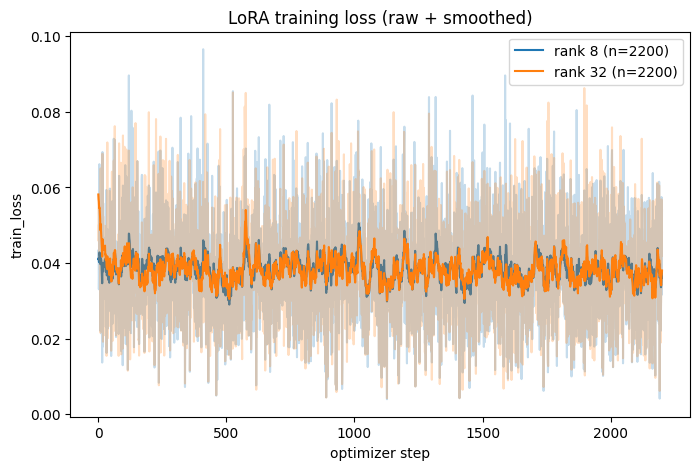

saved /content/drive/MyDrive/DATA266-Lab2/p2/loss_curves.png


In [22]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import matplotlib.pyplot as plt


def load_loss(run_dir):
    steps, losses = [], []
    for ef in sorted(Path(run_dir).rglob("events.out.tfevents.*")):
        ea = EventAccumulator(str(ef), size_guidance={"scalars": 0})
        ea.Reload()
        if "train_loss" in ea.Tags().get("scalars", []):
            for e in ea.Scalars("train_loss"):
                steps.append(e.step)
                losses.append(e.value)
    order = sorted(range(len(steps)), key=lambda i: steps[i])
    return [steps[i] for i in order], [losses[i] for i in order]


def ema(values, weight=0.9):
    out, last = [], None
    for v in values:
        last = v if last is None else last * weight + (1 - weight) * v
        out.append(last)
    return out


fig, ax = plt.subplots(figsize=(8, 5))
for rank, color in ((8, "tab:blue"), (32, "tab:orange")):
    steps, losses = load_loss(RUN_DIRS[rank])
    if not steps:
        print(f"rank {rank}: no tensorboard scalars found yet")
        continue
    ax.plot(steps, losses, color=color, alpha=0.25)
    ax.plot(steps, ema(losses), color=color, label=f"rank {rank} (n={len(steps)})")
ax.set_xlabel("optimizer step")
ax.set_ylabel("train_loss")
ax.legend()
ax.set_title("LoRA training loss (raw + smoothed)")
fig.savefig(DRIVE_ROOT / "loss_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print("saved", DRIVE_ROOT / "loss_curves.png")


### Training results table

In [23]:
import pandas as pd

rows = []
for rank in (8, 32):
    run_dir = RUN_DIRS[rank]
    cfg = {8: cfg8, 32: cfg32}[rank]
    stats = j.loads((run_dir / "stats.json").read_text())
    rows.append({
        "rank": rank,
        "trainable_params": count_lora_params(run_dir),
        "learning_rate": cfg["learning_rate"],
        "steps": stats["steps_finished"],
        "batch_size": cfg["train_batch_size"],
        "gradient_accumulation": cfg["gradient_accumulation_steps"],
        "effective_batch_size": cfg["train_batch_size"] * cfg["gradient_accumulation_steps"],
        "peak_memory_gb": round(stats["peak_memory_mib"] / 1024, 2),
        "peak_memory_verdict": "PASS" if stats["peak_memory_mib"] / 1024 < 16 else "FAIL",
        "wall_clock_min": round(stats["wall_clock_s"] / 60, 1),
        "gpu_hours": round(stats["gpu_hours"], 2),
    })
RESULTS_TABLE = pd.DataFrame(rows)
RESULTS_TABLE.to_csv(DRIVE_ROOT / "results_table.csv", index=False)
print(RESULTS_TABLE.to_string(index=False))


 rank  trainable_params  learning_rate  steps  batch_size  gradient_accumulation  effective_batch_size  peak_memory_gb peak_memory_verdict  wall_clock_min  gpu_hours
    8           1594368         0.0001   2200           1                      4                     4            4.44                PASS            69.7       1.16
   32           6377472         0.0001   2200           1                      4                     4            4.52                PASS            74.6       1.24


### Push to Hugging Face

In [24]:
from huggingface_hub import HfApi

HF_USER = "itzmnv"
MODEL_README = """---
license: other
license_name: creativeml-openrail-m
license_link: https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/blob/main/LICENSE.md
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
tags:
- lora
- stable-diffusion
- text-to-image
---

# SD 1.5 LoRA (rank {rank}) fine-tuned on Pokemon BLIP captions

- **Base model:** stable-diffusion-v1-5/stable-diffusion-v1-5 (CreativeML OpenRAIL-M)
- **Data:** reach-vb/pokemon-blip-captions (CC BY-NC-SA 4.0) -- Pokemon characters are copyrighted;
  this model and its outputs are for **non-commercial research only**
- **LoRA rank:** {rank}
- **Steps:** {steps} | **Learning rate:** {lr} | **Effective batch size:** {batch} (batch {bs} x gradient accumulation {accum})
- **Peak GPU memory:** {mem:.2f} GB | **Wall-clock time:** {wall:.1f} min | **GPU-hours:** {gpuh:.2f}
- **Trainable parameters:** {params:,} (counted from the saved weights, not estimated)

**Limitations:** trained on a small (825-image), single-style dataset with short, generic BLIP captions;
expect it to default to a plain white background and to lean on colour words more than creature identity
or pose (see the dataset limitations in the training notebook). Not yet evaluated against its sibling run --
the final choice between rank 8 and rank 32, and a full model card with generation results, come after
evaluation (p2_generate_eval.ipynb).
"""

api = HfApi()
hf_urls = {}
for rank in (8, 32):
    repo_id = f"{HF_USER}/data266-lab2-sd15-pokemon-lora-r{rank}"
    run_dir = RUN_DIRS[rank]
    cfg = {8: cfg8, 32: cfg32}[rank]
    stats = j.loads((run_dir / "stats.json").read_text())
    readme = MODEL_README.format(
        rank=rank, steps=stats["steps_finished"], lr=cfg["learning_rate"],
        batch=cfg["train_batch_size"] * cfg["gradient_accumulation_steps"],
        bs=cfg["train_batch_size"], accum=cfg["gradient_accumulation_steps"],
        mem=stats["peak_memory_mib"] / 1024, wall=stats["wall_clock_s"] / 60,
        gpuh=stats["gpu_hours"], params=count_lora_params(run_dir),
    )
    (run_dir / "README.md").write_text(readme)
    api.create_repo(repo_id, repo_type="model", exist_ok=True, private=False)
    api.upload_file(path_or_fileobj=str(run_dir / "pytorch_lora_weights.safetensors"),
                     path_in_repo="pytorch_lora_weights.safetensors", repo_id=repo_id)
    api.upload_file(path_or_fileobj=str(run_dir / "README.md"), path_in_repo="README.md", repo_id=repo_id)
    hf_urls[rank] = f"https://huggingface.co/{repo_id}"
    print(hf_urls[rank])


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ..._lora_weights.safetensors: 100%|##########| 6.41MB / 6.41MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


No files have been modified since last commit. Skipping to prevent empty commit.


... (4 outputs left out)

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


No files have been modified since last commit. Skipping to prevent empty commit.


https://huggingface.co/itzmnv/data266-lab2-sd15-pokemon-lora-r32
